# Barren-plateau diagnoser: executable validation

This notebook tests the lazy top-level `qasp.barren_plateau_diagnoser` on the
three QASP model families: parameterized classifiers, trainable quantum
kernels, and reinforcement-learning policies.

For random initializations $\theta_s$, QASP reports two distinct concentration
statistics:

$$
\widehat{\mathrm{Var}}[C]
=\frac{1}{N-1}\sum_s(C_s-\bar C)^2,
\qquad
\widehat{\mathrm{Var}}[\bar E]
=\frac{1}{N-1}\sum_s(\bar E_s-\overline{\bar E})^2,
$$

where $C_s$ is the task cost and $\bar E_s$ is the arithmetic mean of the raw
quantum expectation outputs. The result also retains the componentwise
variance of every expectation. These are variances **across initializations**,
not the within-state measurement variance $\langle O^2\rangle-\langle O\rangle^2$.

All cells contain assertions, so a complete execution is also an integration
test of the public API.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "examples":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "examples" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import qasp
from qasp import (
    barren_plateau_diagnoser,
    create_classifier,
    create_kernel,
    create_model,
    target_alignment,
)

assert callable(qasp.barren_plateau_diagnoser)
assert "barren_plateau_diagnoser" in qasp.__all__
print("QASP imported from:", Path(qasp.__file__).resolve())

Matplotlib is building the font cache; this may take a moment.


QASP imported from: /Users/andresequeira/.codex/.chatgpt-projects/g-p-6a882bb0b13081919a864d57162a89ea/qasp_bp_scaling_revision_20260929/qasp/__init__.py


## Shared validation helpers

`check_result` independently recomputes every reported final variance from the
returned samples. It also checks that the final entry of each online variance
curve agrees with the corresponding batch calculation.

In [2]:
def snapshot(model):
    owner = model.qlayer
    return [parameter.detach().clone() for parameter in owner.parameters()]


def assert_restored(model, before):
    after = list(model.qlayer.parameters())
    assert len(before) == len(after)
    assert all(torch.equal(left, right) for left, right in zip(before, after))


def check_result(result):
    cost_samples = np.asarray(result["cost_samples"], dtype=float)
    expectation_samples = np.asarray(result["expectation_samples"], dtype=float)
    expectation_value_samples = expectation_samples.mean(axis=1)

    assert result["n_samples"] == len(cost_samples)
    assert np.isfinite(cost_samples).all()
    assert np.isfinite(expectation_samples).all()
    assert result["cost_variance"] == result["variance"]
    np.testing.assert_allclose(
        result["cost_variance"], np.var(cost_samples, ddof=result["ddof"])
    )
    np.testing.assert_allclose(
        result["expectation_variance"],
        np.var(expectation_samples, axis=0, ddof=result["ddof"]),
    )
    np.testing.assert_allclose(
        result["expectation_value_samples"], expectation_value_samples
    )
    np.testing.assert_allclose(
        result["expectation_value_variance"],
        np.var(expectation_value_samples, ddof=result["ddof"]),
    )
    np.testing.assert_allclose(
        result["cost_variance_by_sample"][-1], result["cost_variance"]
    )
    np.testing.assert_allclose(
        result["expectation_variance_by_sample"][-1],
        result["expectation_variance"],
    )
    np.testing.assert_allclose(
        result["expectation_value_variance_by_sample"][-1],
        result["expectation_value_variance"],
    )
    np.testing.assert_array_equal(
        result["sample_counts"], np.arange(1, result["n_samples"] + 1)
    )
    return result


def angle_ansatz(n_qubits):
    return {
        "n_layers": 1,
        "rotations": "Y",
        "include_imprimitive": True,
        "imprimitive": "CZ",
        "imprimitive_pattern": "chain",
        "reuploading": False,
    }


def angle_features(n_qubits):
    return {
        "features": n_qubits,
        "rotations": "Y",
        "imprimitive_pattern": "chain",
    }


N_SAMPLES = 24
SEED = 19

## 1. Binary expectation classifier with MSE

The circuit measures `Z 0`, `ZZ 0 1`, and `X 1`. The binary classifier score
is their arithmetic mean, while the diagnosed cost is MSE against the positive
class. This makes cost concentration and raw expectation concentration visibly
different quantities.

In [3]:
expectation_classifier = create_classifier(
    {
        "ansatz": "AngleAnsatz",
        "ansatz_config": angle_ansatz(2),
        "feature_map": "AngleEmbedding",
        "feature_map_config": angle_features(2),
        "readout": "expectation",
        "observables": ["Z 0", "ZZ 0 1", "X 1"],
        "init": "zeros",
        "device": "default.qubit",
        "diff_method": "backprop",
    },
    n_qubits=2,
    n_classes=2,
)

fixed_x = torch.tensor([0.25, -0.40])
before = snapshot(expectation_classifier)
classifier_result = check_result(
    barren_plateau_diagnoser(
        expectation_classifier,
        n_samples=N_SAMPLES,
        initialization="random_-pi_pi",
        state=fixed_x,
        targets=torch.tensor(1),
        objective="mean_squared_error",
        seed=SEED,
        return_samples=True,
    )
)
assert_restored(expectation_classifier, before)
assert classifier_result["model_type"] == "classifier"
assert classifier_result["state_mode"] == "fixed"
assert classifier_result["cost"] == "mean_squared_error"
assert classifier_result["expectation_samples"].shape == (N_SAMPLES, 3)

pd.Series({
    "cost variance": classifier_result["cost_variance"],
    "mean-expectation variance": classifier_result["expectation_value_variance"],
    "mean cost": classifier_result["mean"],
})

cost variance                0.241674
mean-expectation variance    0.051485
mean cost                    1.206075
dtype: float64

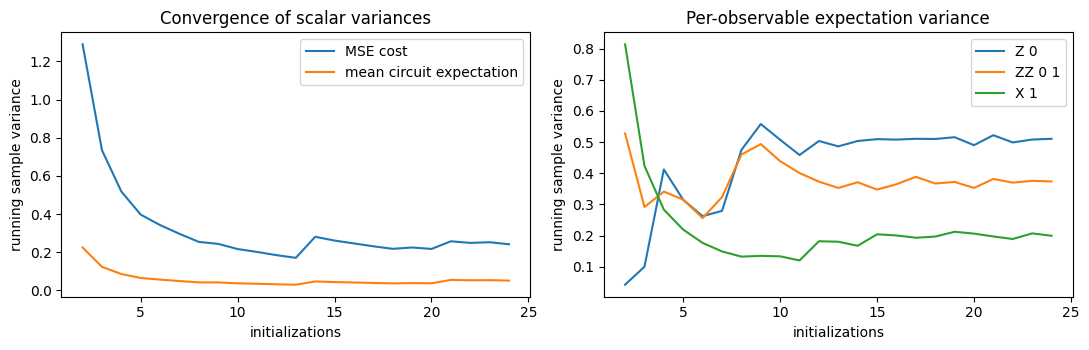

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = classifier_result["sample_counts"]
axes[0].plot(counts, classifier_result["cost_variance_by_sample"], label="MSE cost")
axes[0].plot(
    counts,
    classifier_result["expectation_value_variance_by_sample"],
    label="mean circuit expectation",
)
axes[0].set(xlabel="initializations", ylabel="running sample variance")
axes[0].set_title("Convergence of scalar variances")
axes[0].legend()

for index, label in enumerate(["Z 0", "ZZ 0 1", "X 1"]):
    axes[1].plot(
        counts,
        classifier_result["expectation_variance_by_sample"][:, index],
        label=label,
    )
axes[1].set(xlabel="initializations", ylabel="running sample variance")
axes[1].set_title("Per-observable expectation variance")
axes[1].legend()
fig.tight_layout()
plt.show()

## 2. Born-probability classifier

A Born circuit does not directly return Pauli expectations. QASP therefore
reconstructs each local value
$\langle Z_j\rangle=\sum_z(-1)^{z_j}p(z)$ from the raw basis distribution,
before the majority decoder aggregates basis states into classes.

In [5]:
born_classifier = create_classifier(
    {
        "ansatz": "AngleAnsatz",
        "ansatz_config": angle_ansatz(3),
        "feature_map": "AngleEmbedding",
        "feature_map_config": angle_features(3),
        "readout": "probabilities",
        "decoder": "majority",
        "measurement_qubits": [0, 1, 2],
        "majority_blocks": [(0, 1, 2)],
        "init": "small_normal",
        "device": "default.qubit",
        "diff_method": "backprop",
    },
    n_qubits=3,
    n_classes=2,
)

born_result = check_result(
    barren_plateau_diagnoser(
        born_classifier,
        n_samples=N_SAMPLES,
        state=torch.tensor([0.10, -0.20, 0.35]),
        output_index=1,
        seed=SEED,
        return_samples=True,
    )
)
assert born_result["cost"] == "class_probability[1]"
assert born_result["expectation_samples"].shape == (N_SAMPLES, 3)
assert np.abs(born_result["expectation_samples"]).max() <= 1.0 + 1e-6

pd.DataFrame(
    {
        "observable": ["Z 0", "Z 1", "Z 2"],
        "variance": born_result["expectation_variance"],
    }
)

,observable,variance
0,Z 0,0.676206
1,Z 1,0.463979
2,Z 2,0.525073


## 3. Trainable fidelity kernel

For a fixed pair `(x, y)`, the default cost is the kernel similarity. The raw
quantum outputs are the configured zero-projector expectations used to build
that similarity.

In [6]:
kernel = create_kernel(
    {
        "kernel_type": "fidelity",
        "feature_map": "AngleEmbedding",
        "feature_map_config": angle_features(2),
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": 2,
            "imprimitive_pattern": "ring",
            "reuploading": True,
        },
        "projectors": ["P 0", "P 1"],
        "init": "zeros",
        "device": "default.qubit",
    },
    n_qubits=2,
)

kernel_pair = (np.array([0.10, 0.20]), np.array([0.65, -0.30]))
before = snapshot(kernel)
kernel_result = check_result(
    barren_plateau_diagnoser(
        kernel,
        n_samples=N_SAMPLES,
        state=kernel_pair,
        initialization="random_-pi_pi",
        seed=SEED,
        return_samples=True,
    )
)
assert_restored(kernel, before)
assert kernel_result["model_type"] == "kernel"
assert kernel_result["cost"] == "kernel_similarity"
assert kernel_result["expectation_samples"].shape == (N_SAMPLES, 2)

pd.Series({
    "kernel-similarity variance": kernel_result["cost_variance"],
    "mean-projector variance": kernel_result["expectation_value_variance"],
})

kernel-similarity variance    0.002343
mean-projector variance       0.002343
dtype: float64

### Kernel target-alignment cost

The generic `cost_function` path can diagnose the actual trainable-kernel
objective. For a dataset, the fidelity-kernel expectation extractor records
the raw projector values for every distinct input pair.

In [7]:
X_kernel = np.array([
    [0.10, 0.15],
    [0.20, 0.05],
    [0.80, 0.95],
    [0.95, 0.75],
])
y_kernel = np.array([0, 0, 1, 1])

kta_result = check_result(
    barren_plateau_diagnoser(
        kernel,
        n_samples=12,
        state=X_kernel,
        initialization="small_normal",
        cost_function=lambda model, X: -target_alignment(model.gram(X), y_kernel),
        seed=SEED,
        return_samples=True,
    )
)
assert kta_result["cost"] == "<lambda>"
# 4 choose 2 pairs, with two projector expectations for each pair.
assert kta_result["expectation_samples"].shape == (12, 12)
kta_result["cost_variance"]

5.303521297010988e-07

## 4. Reinforcement-learning Born policy

The selected cost is action probability 1. As for the Born classifier, the
circuit-level outputs are local Z expectations reconstructed from the raw
basis probabilities before contiguous action decoding.

In [8]:
policy = create_model(
    "PQCBorn",
    {
        "ansatz": "AngleAnsatz",
        "ansatz_config": angle_ansatz(2),
        "feature_map": "AngleEmbedding",
        "feature_map_config": angle_features(2),
        "n_actions": 2,
        "init": "zeros",
        "device": "default.qubit",
        "diff_method": "backprop",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": [0, 1],
        "parity_cnot_decomposition": False,
        "policy": "contiguous-like",
        "training_method": "probs",
    },
    n_qubits=2,
)

policy_result = check_result(
    barren_plateau_diagnoser(
        policy,
        n_samples=N_SAMPLES,
        state=torch.tensor([0.15, -0.25]),
        output_index=1,
        seed=SEED,
        return_samples=True,
    )
)
assert policy_result["model_type"] == "policy"
assert policy_result["cost"] == "action_probability[1]"
assert policy_result["expectation_samples"].shape == (N_SAMPLES, 2)
assert np.logical_and(
    policy_result["cost_samples"] >= 0,
    policy_result["cost_samples"] <= 1,
).all()
policy_result["cost_variance"]

0.13248383825804494

## 5. Fixed state, random state, and custom extraction

Omitting `state` samples a fresh embedded input for every parameter draw. This
estimates joint state/parameter variance and is intentionally distinct from the
fixed-state conditional experiment. A sampler and both scalar functions can
also be supplied explicitly.

In [9]:
random_state_result = check_result(
    barren_plateau_diagnoser(
        expectation_classifier,
        n_samples=N_SAMPLES,
        state=None,
        state_initialization="random_-1_1",
        output_index=1,
        seed=SEED,
        return_samples=True,
    )
)
assert random_state_result["state_mode"] == "random"
assert random_state_result["state_initialization"] == "random_-1_1"

custom_result = check_result(
    barren_plateau_diagnoser(
        expectation_classifier,
        n_samples=N_SAMPLES,
        state_sampler=lambda index, generator: 2 * torch.rand(
            2, generator=generator
        ) - 1,
        cost_function=lambda model, x: (
            model.predict_proba(x)[1] - 0.75
        ).square(),
        expectation_function=lambda model, x: model._quantum_output(x).mean(),
        seed=SEED,
        return_samples=True,
    )
)
assert custom_result["state_mode"] == "sampler"
assert custom_result["expectation_samples"].shape == (N_SAMPLES, 1)

pd.DataFrame(
    {
        "experiment": ["fixed state", "random state", "custom sampler"],
        "cost variance": [
            classifier_result["cost_variance"],
            random_state_result["cost_variance"],
            custom_result["cost_variance"],
        ],
        "expectation-value variance": [
            classifier_result["expectation_value_variance"],
            random_state_result["expectation_value_variance"],
            custom_result["expectation_value_variance"],
        ],
    }
)

,experiment,cost variance,expectation-value variance
0,fixed state,0.241674,0.051485
1,random state,0.006491,0.109762
2,custom sampler,0.001626,0.109762


## 6. Qubit-width sweep: the barren-plateau scaling experiment

A barren plateau is a statement about scaling with system size, not merely a
small variance at one width. For each entry of `qubit_list`, the factory below
constructs the same one-layer classifier family and measures the global
$Z^{\otimes n}$ observable at a fixed zero input. QASP then draws an independent
ensemble of parameter initializations and estimates

$$
\widehat{\operatorname{Var}}[C_n]
=\frac{1}{N-1}\sum_{s=1}^{N}(C_{n,s}-\bar C_n)^2
$$

independently for every $n$. The notebook uses enough widths to expose the
finite-size trend while remaining an executable example. A publication study
should increase both the width range and sample count and, crucially, repeat
the analysis for gradient variance before claiming a barren plateau.

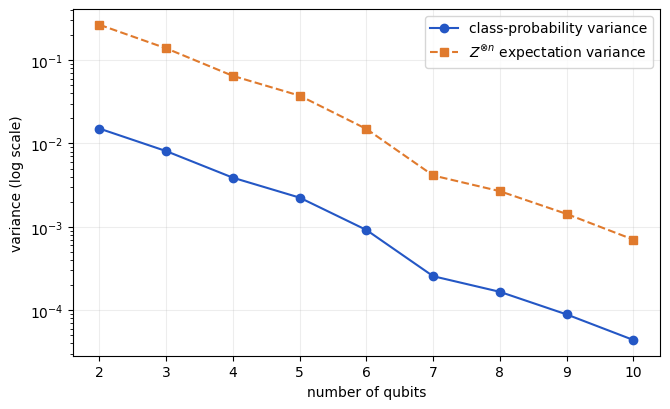

log2 variance slope per qubit: -1.1076399684582388


,n_qubits,cost_variance,expectation_value_variance
0,2,0.015069,0.265885
1,3,0.008088,0.138548
2,4,0.003877,0.064699
3,5,0.002235,0.037432
4,6,0.000915,0.014934
5,7,0.000255,0.004126
6,8,0.000165,0.002672
7,9,0.000089,0.001424
8,10,0.000044,0.000701


In [10]:
def classifier_factory(n_qubits):
    global_z = f'{"Z" * n_qubits} ' + " ".join(
        str(wire) for wire in range(n_qubits)
    )
    return create_classifier(
        {
            "ansatz": "AngleAnsatz",
            "ansatz_config": angle_ansatz(n_qubits),
            "feature_map": "AngleEmbedding",
            "feature_map_config": angle_features(n_qubits),
            "readout": "expectation",
            "observables": [global_z],
            "init": "zeros",
            "device": "default.qubit",
            "diff_method": "backprop",
        },
        n_qubits=n_qubits,
        n_classes=2,
    )


qubit_list = list(range(2, 11))
SWEEP_SAMPLES = 128
sweep = barren_plateau_diagnoser(
    model_factory=classifier_factory,
    qubit_list=qubit_list,
    n_samples=SWEEP_SAMPLES,
    initialization="random_-pi_pi",
    state_factory=lambda n: torch.zeros(n),
    output_index=1,
    seed=SEED,
    return_samples=True,
)

assert sweep["mode"] == "qubit_sweep"
np.testing.assert_array_equal(sweep["qubit_list"], qubit_list)
assert sweep["cost_variance"].shape == (len(qubit_list),)
assert sweep["expectation_value_variance"].shape == (len(qubit_list),)
assert sweep["state_mode"] == "fixed"

for index, n_qubits in enumerate(qubit_list):
    child = check_result(sweep["results_by_qubit"][n_qubits])
    assert child["n_qubits"] == n_qubits
    np.testing.assert_allclose(
        sweep["cost_variance"][index], child["cost_variance"]
    )
    np.testing.assert_allclose(
        sweep["expectation_value_variance"][index],
        child["expectation_value_variance"],
    )

scaling_table = pd.DataFrame(
    {
        "n_qubits": sweep["qubit_list"],
        "cost_variance": sweep["cost_variance"],
        "expectation_value_variance": sweep["expectation_value_variance"],
    }
)
scaling_table.to_csv(
    RESULTS / "barren_plateau_variance_vs_qubits.csv", index=False
)

fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.semilogy(
    qubit_list,
    sweep["cost_variance"],
    "o-",
    color="#2457C5",
    label="class-probability variance",
)
ax.semilogy(
    qubit_list,
    sweep["expectation_value_variance"],
    "s--",
    color="#E07A2D",
    label=r"$Z^{\otimes n}$ expectation variance",
)
ax.set(xlabel="number of qubits", ylabel="variance (log scale)")
ax.set_xticks(qubit_list)
ax.grid(alpha=0.22)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "barren_plateau_variance_vs_qubits.pdf")
fig.savefig(RESULTS / "barren_plateau_variance_vs_qubits.png", dpi=220)
plt.show()

log2_slope = np.polyfit(
    sweep["qubit_list"],
    np.log2(sweep["expectation_value_variance"]),
    deg=1,
)[0]
assert np.isfinite(log2_slope)
print("log2 variance slope per qubit:", log2_slope)
scaling_table

## Cross-module summary

The values below are smoke-test estimates from deliberately small sample
counts; they are not evidence of a barren plateau. A scaling study should keep
the cost, state protocol, initializer, circuit family, and observable locality
fixed while increasing system size and should additionally study gradient
variance.

In [11]:
results = {
    "expectation classifier / MSE": classifier_result,
    "Born classifier / class probability": born_result,
    "fidelity kernel / similarity": kernel_result,
    "fidelity kernel / target alignment": kta_result,
    "Born policy / action probability": policy_result,
    "expectation classifier / random state": random_state_result,
    "expectation classifier / custom": custom_result,
}

summary = pd.DataFrame.from_dict(
    {
        name: {
            "model type": result["model_type"],
            "state mode": result["state_mode"],
            "samples": result["n_samples"],
            "parameters": result["n_parameters"],
            "cost variance": result["cost_variance"],
            "expectation-value variance": result["expectation_value_variance"],
            "raw expectation outputs": len(result["expectation_variance"]),
        }
        for name, result in results.items()
    },
    orient="index",
)

assert np.isfinite(summary[["cost variance", "expectation-value variance"]]).all().all()
print("All barren_plateau_diagnoser notebook assertions passed.")
summary

All barren_plateau_diagnoser notebook assertions passed.


,model type,state mode,samples,parameters,cost variance,expectation-value variance,raw expectation outputs
expectation classifier / MSE,classifier,fixed,24,2,2.416736e-01,0.051485,3
Born classifier / class probability,classifier,fixed,24,3,1.270923e-01,0.211989,3
fidelity kernel / similarity,kernel,fixed,24,8,2.343500e-03,0.002343,2
fidelity kernel / target alignment,kernel,fixed,12,8,5.303521e-07,0.000004,12
Born policy / action probability,policy,fixed,24,2,1.324838e-01,0.224138,2
expectation classifier / random state,classifier,random,24,2,6.491131e-03,0.109762,3
expectation classifier / custom,classifier,sampler,24,2,1.626163e-03,0.109762,1
